### Goals

- load models trained with different setups
- with each model, predict the test set  
- compute metrics







In [18]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
from pprint import pformat

import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [2]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics


### Examples of how to filter wandb runs:

example_filters = {


    "group" : "17/5 single-bi-trimodal",
    "config.image_encoder.use": True,
    "config.batch_size": {'$gt': 10}, #Greater than
    "config.batch_size": {'$lte': 10}, #Less than or equal
    
	"$and": [{
		'created_at': {
			"$lt": '2022-03-09T10',
			"$gt": '2022-03-07T17'
		}
	}]
    
}

In [3]:
# Define the filter criteria
'''filter_criteria = {
    'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    
    "group" : "25/5 eval freezing enc, modalities, n of examples",
    "config.seed" : 420,
    "$or": [{
        'config.train_examples_per_class': {
            "$gt": '200',
        }
    },
        {
        'config.train_examples_per_class': {
            "$lt": '200',
        }
    }
    ]
}'''


'filter_criteria = {\n    \'config.image_encoder.use\': True,\n    #\'config.tabular_encoder.use\': True,\n    #\'config.loc_encoder.use\': True,\n    \n    "group" : "25/5 eval freezing enc, modalities, n of examples",\n    "config.seed" : 420,\n    "$or": [{\n        \'config.train_examples_per_class\': {\n            "$gt": \'200\',\n        }\n    },\n        {\n        \'config.train_examples_per_class\': {\n            "$lt": \'200\',\n        }\n    }\n    ]\n}'

In [4]:
# Define the filter criteria
filter_criteria = {
    #'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    
    "group" : "21/6 testing devel",
    #"config.seed" : 420,


    
}





In [5]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 6


In [6]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
#selected_models = [model for model in models  if model['config']['train dst size'] > 10000]  
#print(len(selected_models))
#models = selected_models

"\nIn some cases, the wandb API filtering doesn't work;\nIf I get 0 models returned, I need to \n    1. remove the problematic filter\n    2. get all the runs\n    3. filter manually as below\n"

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12


In [8]:
CHECKPOINT_TYPE = 'last'

for model_dict in tqdm.tqdm(models):

    metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'val', CHECKPOINT_TYPE)
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    
    #This is just to get rid of wandb objects that are un-picklable wtf
    model_dict['summary'] = dict(model_dict['summary'])
    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])
    model_dict['summary']['val conf matrix'] = None
    model_dict['summary']['train conf matrix'] = None
    
    

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:43<00:00,  7.31s/it]


In [11]:
#selected_models = [model for model in models  if model['config']['train_examples_per_class'] < 1000]  


48

In [107]:
def inspect_objects(d, path=""):
    if isinstance(d, dict):
        for k, v in d.items():
            new_path = f"{path}/{k}" if path else str(k)
            inspect_objects(v, new_path)
    elif isinstance(d, list):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    elif isinstance(d, tuple):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    else:
        print(f"Object at path {path}: {type(d)}")

In [108]:
import pickle
with open('21_6.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [109]:
#with open('filename.pickle', 'rb') as handle:
#    first_set = pickle.load(handle)
with open('21_6.pickle', 'rb') as handle:
    test = pickle.load(handle)


In [44]:
import importlib
importlib.reload(utils)


<module 'utils' from '/home/jan/Documents/EPFL/project_2/notebooks/../utils.py'>

In [10]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [11]:
hyperparams_values

{'seed': [420, 421, 422], 'tabular_encoder': {'use': [False, True]}}

In [12]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_grid_5_split.csv")
labels = labels.loc[labels['split'] == 4].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [13]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [14]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [16]:
len(combinations)

2

In [30]:
#This I need to do in case there is only 1 seed
#hyperparams_values['seed'] = [420]

In [19]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    combo_str = ' '.join(pformat(combo, width=1).split())
    print(combo_str)

    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not model_with_this_config:
            continue
            
        assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
        model_with_this_config = model_with_this_config[0]

        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

{'tabular_encoder': {'use': False}}
{'tabular_encoder': {'use': True}}


In [39]:
print([key for key in performance_per_configuration.keys() if "'train_examples_per_class'}" in key]) 

[]


In [64]:
#frozen_img_enc_models = {key:value for key, value in performance_per_configuration.items() if "'freeze_after': 6" in key}

#models_20_per_class = {key:value for key, value in performance_per_configuration.items() if "'train_examples_per_class': 20}" in key}
#models_100_per_class = {key:value for key, value in performance_per_configuration.items() if "'train_examples_per_class': 100}" in key}
#models_500_per_class = {key:value for key, value in performance_per_configuration.items() if "'train_examples_per_class': 500}" in key}


models_100_per_class = {key:value for key, value in performance_per_configuration.items() if "'train_examples_per_class': 100," in key}
models_500_per_class = {key:value for key, value in performance_per_configuration.items() if "'train_examples_per_class': 500," in key}




In [28]:
def plot_metrics(metrics, metric='accuracy', ylim=(0.2, 1.2) ):
    
    class_names = list(LABEL_MAPPING.keys())
    class_names.append(metric)
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=ylim[0])
    plt.ylim(top=ylim[1])
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show()

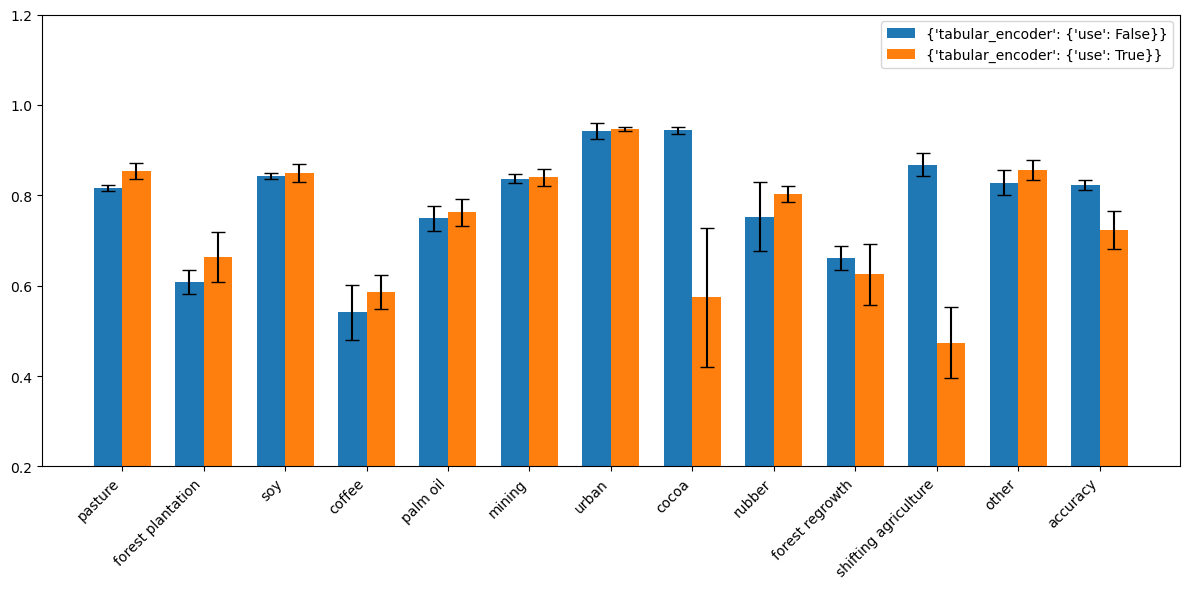

In [29]:
plot_metrics(performance_per_configuration)

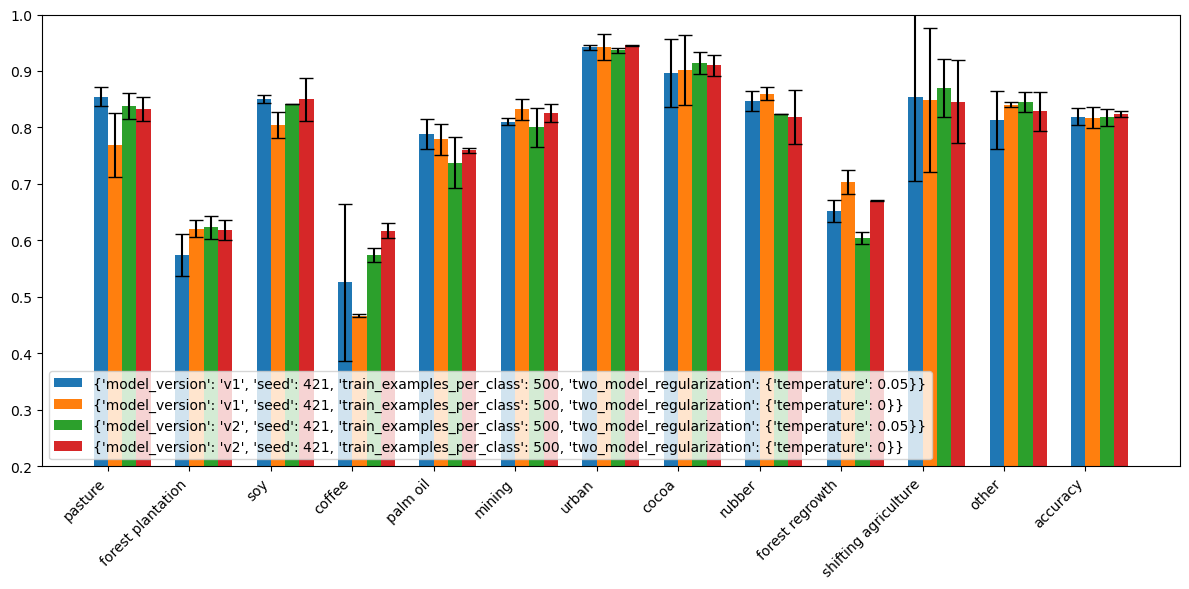

In [67]:
plot_metrics(models_500_per_class)

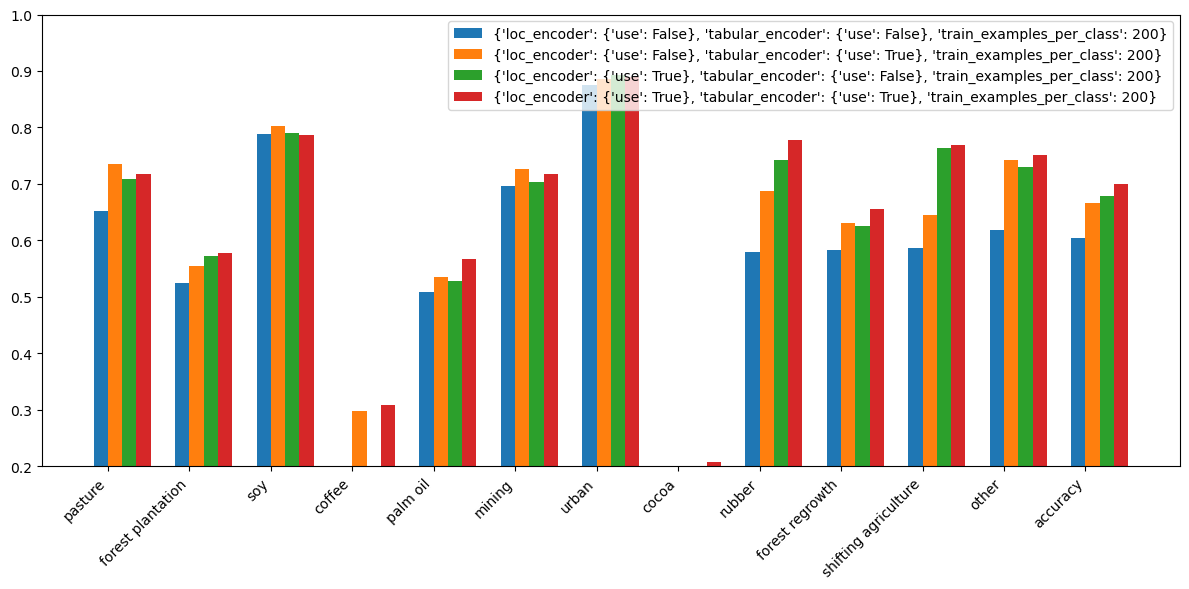

In [47]:
plot_metrics(models_200_per_class)

In [22]:
from sklearn.metrics import classification_report


from model.dataset import LABEL_MAPPING

CLASS_INDICES = [value for key, value in LABEL_MAPPING.items()]
CLASS_NAMES = [key for key in LABEL_MAPPING.keys()]


In [85]:
countries = ['Costa Rica', 'Ghana', 'Cambodia']


In [88]:
model = models[0]
_country = 'Costa Rica'
country_indices = labels.loc[labels.country == _country].index.tolist()
country_targets =  labels.loc[labels.country == _country].driver.map(LABEL_MAPPING).to_numpy()
country_predictions = model['predictions'][country_indices]

_metrics = classification_report(country_targets, country_predictions, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)
pd.DataFrame(_metrics)

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other,micro avg,macro avg,weighted avg
precision,0.0,0.0,0.0,0.318182,0.945578,0.100000,0.960000,0.0,0.0,0.026316,0.0,0.0,0.621528,0.195840,0.844038
recall,0.0,0.0,0.0,0.350000,0.640553,1.000000,0.923077,0.0,0.0,0.250000,0.0,0.0,0.621528,0.263636,0.621528
f1-score,0.0,0.0,0.0,0.333333,0.763736,0.181818,0.941176,0.0,0.0,0.047619,0.0,0.0,0.621528,0.188974,0.708010
support,0.0,0.0,0.0,40.000000,217.000000,1.000000,26.000000,0.0,0.0,4.000000,0.0,0.0,288.000000,288.000000,288.000000


# Compute metrics per country

In [23]:
countries = ['Costa Rica', 'Ghana', 'Cambodia']


performance_per_configuration_per_country = {}



for _country in countries:

    country_indices = labels.loc[labels.country == _country].index.tolist()
    country_targets =  labels.loc[labels.country == _country].driver.map(LABEL_MAPPING).to_numpy()
    
    performance_per_configuration_per_country[_country] = {}


    for combo in combinations:

        metrics_per_random_seed = []
        combo_str = ' '.join(pformat(combo, width=1).split())

        #Compute metrics per each random seed separately
        for seed in hyperparams_values['seed']:
            combo['seed'] = seed 

            #Get all models that have the configuration setup 
            model_with_this_config = get_models_with_config(models, combo)
            if not model_with_this_config:
                continue

            assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
            model_with_this_config = model_with_this_config[0]

            country_predictions = model_with_this_config['predictions'][country_indices]

            country_metrics = classification_report(country_targets, country_predictions, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)


            metrics_per_random_seed.append(pd.DataFrame(country_metrics))

        if not metrics_per_random_seed:
            print("no metrics for: ", combo)
            continue


        # Concatenate DataFrames along a new axis
        concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

        # Compute the mean along the new axis
        mean_df = concat_df.groupby(level=1).mean()

        # Compute the standard deviation along the new axis
        std_df = concat_df.groupby(level=1).std()   



        performance_per_configuration_per_country[_country][combo_str] = {}
        performance_per_configuration_per_country[_country][combo_str]['mean'] = mean_df
        performance_per_configuration_per_country[_country][combo_str]['std'] = std_df



        

In [93]:
_country = "Ghana"
models_100_per_class_country = {key:value for key, value in performance_per_configuration_per_country[_country].items() if "'train_examples_per_class': 100," in key}
models_500_per_class_country = {key:value for key, value in performance_per_configuration_per_country[_country].items() if "'train_examples_per_class': 500," in key}


In [98]:
models_100_per_class_country["{'model_version': 'v1', 'seed': 421, 'train_examples_per_class': 100, 'two_model_regularization': {'temperature': 0.05}}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.475936,0.623210,0.776719,0.949725,0.0,0.5,0.0,0.0,0.899757,0.277133,0.880946
precision,0.0,0.0,0.0,0.0,0.833333,0.955076,0.666667,0.911681,0.0,0.5,0.0,0.0,0.899757,0.322230,0.889219
recall,0.0,0.0,0.0,0.0,0.333333,0.469697,0.931034,0.991211,0.0,0.5,0.0,0.0,0.899757,0.268773,0.899757
support,0.0,12.0,0.0,0.0,24.000000,132.000000,29.000000,1024.000000,12.0,2.0,2.0,0.0,1237.000000,1237.000000,1237.000000


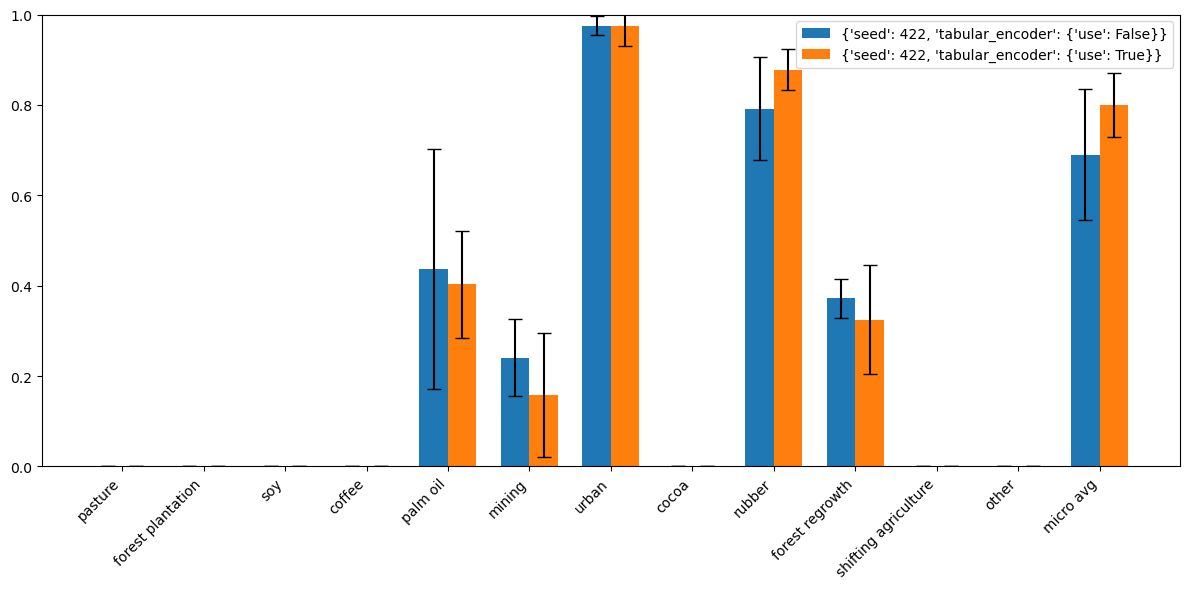

In [32]:
plot_metrics(performance_per_configuration_per_country['Cambodia'], metric='micro avg', ylim=(0,1))


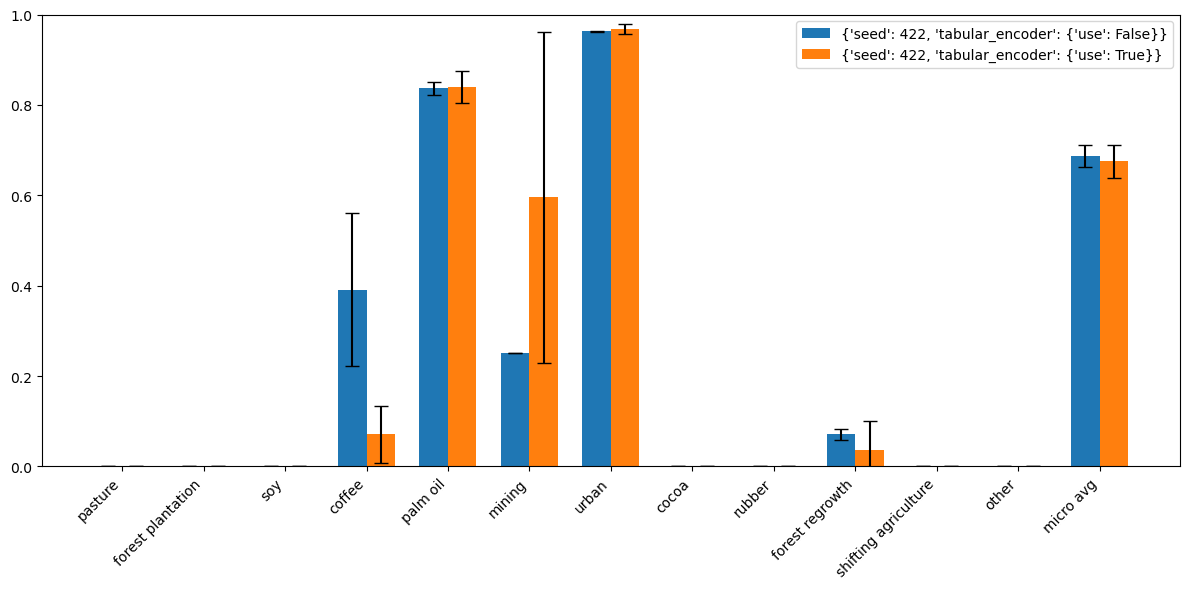

In [31]:
plot_metrics(performance_per_configuration_per_country['Costa Rica'], metric='micro avg', ylim=(0,1))


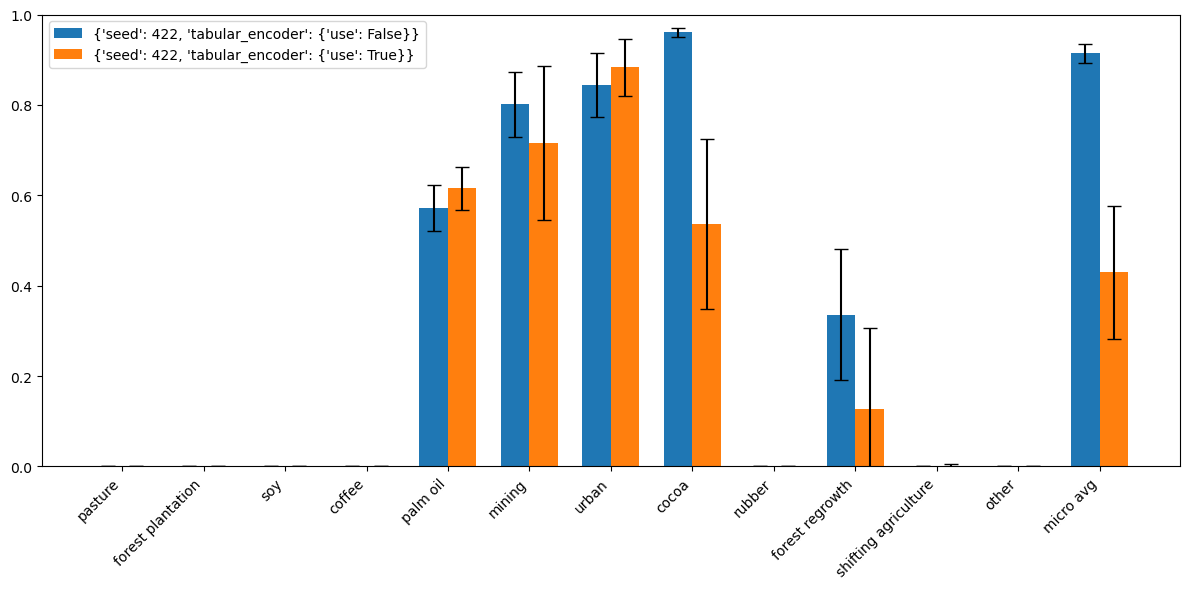

In [30]:
plot_metrics(performance_per_configuration_per_country['Ghana'], metric='micro avg', ylim=(0,1))


In [46]:
labels['model2_pred'] = models[2]['predictions']
labels['model2_pred'] = labels['model2_pred'].map(inverse_label_mapping)

In [55]:
labels['model_1_correct'] = labels.driver == labels.model1_pred
labels['model_2_correct'] = labels.driver == labels.model2_pred

In [56]:
#labels['geometry'] = gpd.GeoSeries.from_wkt(labels['geometry'])
gpd.GeoDataFrame(labels).to_file('../data/tmp/preds.gpkg')

In [57]:
labels

,driver,sampleid,dataset,country,geometry,block_id,split,model1_pred,model2_pred,model_1_correct,model_2_correct
0,coffee,190000083,manual_annotation.csv,Costa Rica,POINT (-84.25407 10.14892),92.0,4,coffee,mining,True,False
1,coffee,190000084,manual_annotation.csv,Costa Rica,POINT (-84.37103 10.14003),92.0,4,palm oil,cocoa,False,False
2,coffee,190000085,manual_annotation.csv,Costa Rica,POINT (-84.38558 10.13114),92.0,4,palm oil,cocoa,False,False
3,coffee,190000086,manual_annotation.csv,Costa Rica,POINT (-84.32467 10.11335),92.0,4,cocoa,cocoa,False,False
4,coffee,190000087,manual_annotation.csv,Costa Rica,POINT (-84.40768 10.05999),92.0,4,palm oil,cocoa,False,False
...,...,...,...,...,...,...,...,...,...,...,...
5072,forest plantation,10655614,mapbiomas.csv,Brazil,POINT (-42.75639 -19.48473),33.0,4,forest plantation,coffee,True,False
5073,forest plantation,10655563,mapbiomas.csv,Brazil,POINT (-42.41844 -19.46694),33.0,4,forest plantation,forest plantation,True,True
5074,forest plantation,10656797,mapbiomas.csv,Brazil,POINT (-43.34335 -19.97386),33.0,4,forest plantation,forest plantation,True,True
5075,forest plantation,10653072,mapbiomas.csv,Brazil,POINT (-42.43623 -18.53314),33.0,4,forest plantation,forest plantation,True,True


In [40]:
models[2]['predictions']

{'seed': 421,
 'epochs': 75,
 'batch_size': 64,
 'classifier': {'type': 'transformer',
  'attention_heads': 8,
  'transformer_layers': 3},
 'in_channels': 4,
 'loc_encoder': {'use': True, 'positional_embedding': 'cartesian3d'},
 'n_parameters': 13160333,
 'val_dst_size': 5077,
 'weight_decay': 0.002,
 'embedding_dim': 128,
 'image_encoder': {'use': True,
  'type': 'cnn',
  'backbone': 'resnet18',
  'moco_weights': False,
  'freezing_patience': 4,
  'pretrained_backbone': True},
 'learning_rate': 0.0005,
 'model_version': 'v1',
 'folds_to_split': {'column': 'split',
  'mapping': {'0': 'train',
   '1': 'train',
   '2': 'train',
   '3': 'train',
   '4': 'val'}},
 'train_dst_size': 6000,
 'use_forestloss': True,
 'tabular_encoder': {'use': True,
  'type': 'token',
  'dataset': 'deduce',
  'temporal_processing': 'dynamic'},
 'randomize_labels': False,
 'forestloss_params': {'sigma': 6, 'kernel_size': 15, 'apply_after_layer': 3},
 'early_stopping_patience': 75,
 'train_examples_per_class': 5

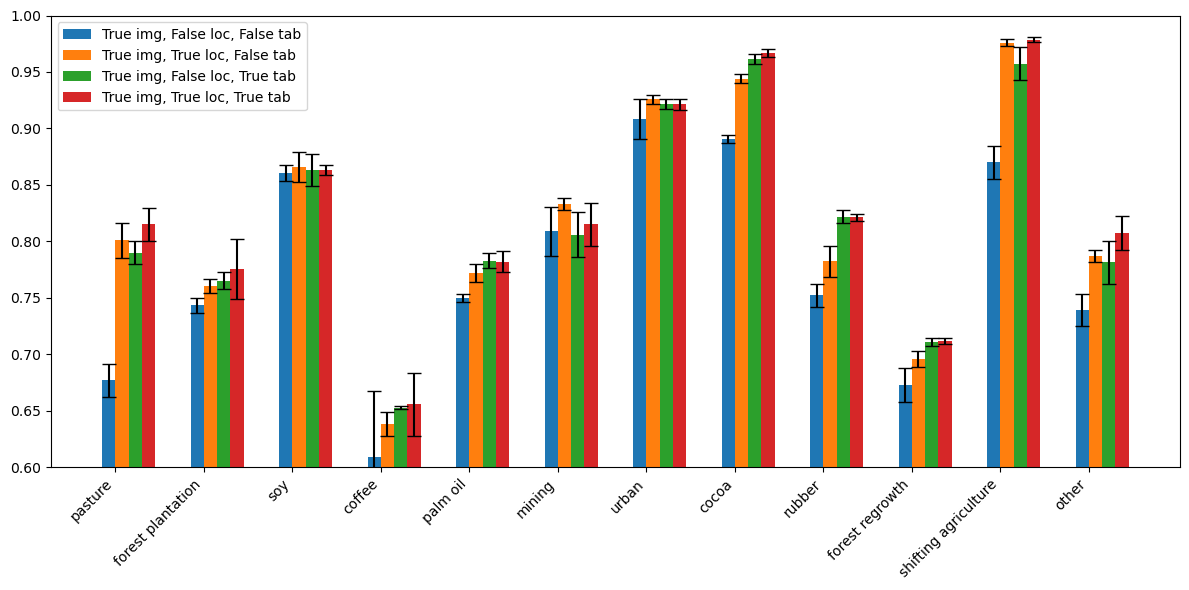

In [195]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(list(performance_per_configuration.keys())): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.6)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

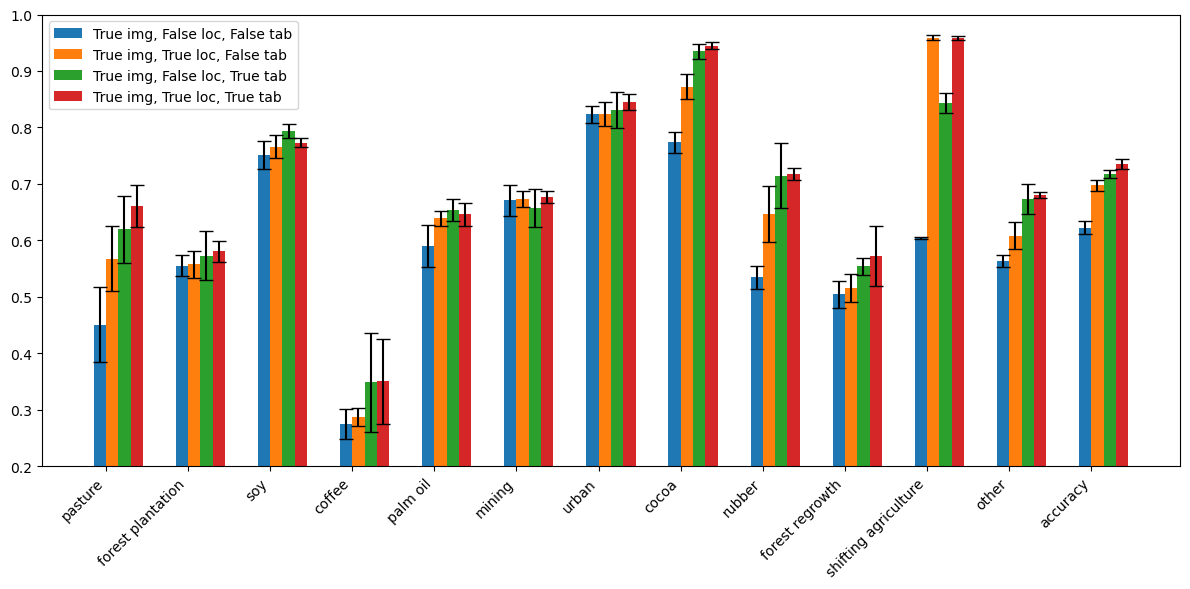

In [44]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()